In [1]:
import pandas as pd
import sklearn

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
data = {
    "income": [25000, 50000, 30000, 80000, 20000,
               60000, 35000, 90000, 28000, 70000],
    "credit_score": [550, 750, 600, 800, 520,
                     720, 650, 820, 580, 780],
    "loan_amount": [200000, 100000, 250000, 150000, 300000,
                    120000, 180000, 100000, 250000, 130000],
    "late_payments": [4, 0, 3, 0, 5, 1, 2, 0, 4, 0],
    "creditworthy": ["No", "Yes", "No", "Yes", "No",
                     "Yes", "No", "Yes", "No", "Yes"]
}

df = pd.DataFrame(data)

print(df)

   income  credit_score  loan_amount  late_payments creditworthy
0   25000           550       200000              4           No
1   50000           750       100000              0          Yes
2   30000           600       250000              3           No
3   80000           800       150000              0          Yes
4   20000           520       300000              5           No
5   60000           720       120000              1          Yes
6   35000           650       180000              2           No
7   90000           820       100000              0          Yes
8   28000           580       250000              4           No
9   70000           780       130000              0          Yes


In [5]:
X = df[["income", "credit_score", "loan_amount", "late_payments"]]
y = df["creditworthy"]

print("Input data:")
print(X.head())

print("\nOutput data:")
print(y.head())

Input data:
   income  credit_score  loan_amount  late_payments
0   25000           550       200000              4
1   50000           750       100000              0
2   30000           600       250000              3
3   80000           800       150000              0
4   20000           520       300000              5

Output data:
0     No
1    Yes
2     No
3    Yes
4     No
Name: creditworthy, dtype: object


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 8
Testing rows: 2


In [10]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, random_state=42)

model.fit(X_train, y_train)

print("Credit Scoring Model trained successfully!")

Credit Scoring Model trained successfully!


In [11]:
y_pred = model.predict(X_test)

print("Actual Results:")
print(y_test.tolist())

print("\nPredicted Results:")
print(y_pred.tolist())

Actual Results:
['No', 'Yes']

Predicted Results:
['No', 'Yes']


In [12]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 100.0 %


In [13]:
new_person = pd.DataFrame({
    "income": [50000],
    "credit_score": [720],
    "loan_amount": [150000],
    "late_payments": [1]
})

prediction = model.predict(new_person)

print("Creditworthiness Prediction:", prediction[0])

Creditworthiness Prediction: Yes


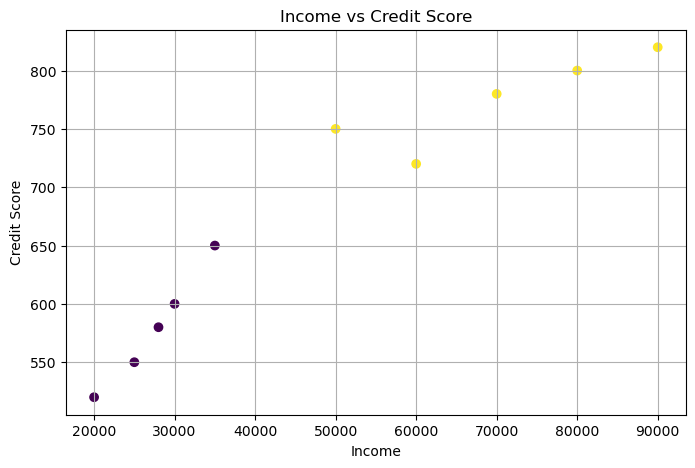

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["income"],
    df["credit_score"],
    c=df["creditworthy"].map({"No": 0, "Yes": 1})
)

plt.xlabel("Income")
plt.ylabel("Credit Score")
plt.title("Income vs Credit Score")
plt.grid(True)

plt.show()

              precision    recall  f1-score   support

          No       1.00      1.00      1.00         1
         Yes       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2



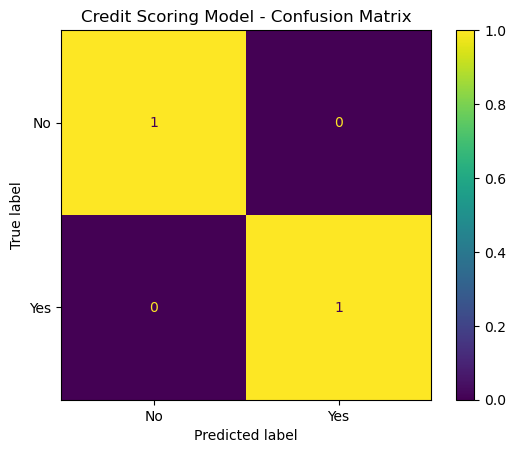

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

plt.title("Credit Scoring Model - Confusion Matrix")
plt.show()

In [16]:
income = int(input("Enter annual income: "))
credit_score = int(input("Enter credit score: "))
loan_amount = int(input("Enter loan amount: "))
late_payments = int(input("Enter number of late payments: "))

new_person = pd.DataFrame({
    "income": [income],
    "credit_score": [credit_score],
    "loan_amount": [loan_amount],
    "late_payments": [late_payments]
})

prediction = model.predict(new_person)

print("\nCredit Scoring Result:", prediction[0])

Enter annual income:  1326637
Enter credit score:  673993
Enter loan amount:  637838920
Enter number of late payments:  1



Credit Scoring Result: Yes


In [17]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [18]:
import streamlit as st

print("Streamlit installed successfully!")

Streamlit installed successfully!


In [19]:
import joblib

joblib.dump(model, "credit_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [20]:
import os

print(os.getcwd())
print(os.path.exists("credit_model.pkl"))

C:\Users\ELCOT
True
